### Regularization Techniques - Ridge, Lasso and ElasticNet

      Feature      Coeff
0      MedInc   0.330903
1    HouseAge  -0.002101
2    AveRooms  -0.024538
3   AveBedrms  -0.368671
4  Population   0.000088
5    AveOccup  -0.069699
6    Latitude  10.108677
7   Longitude   1.347982


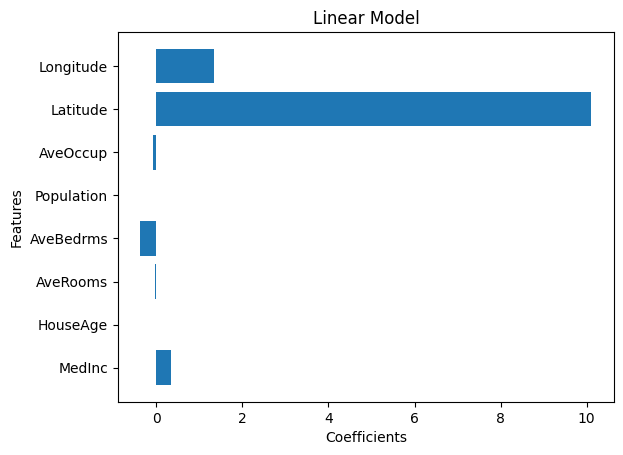

Linear Model 
 MSE: 0.3382442822280913 
 R2: 0.7019098010657341 

      Feature     Coeff
0      MedInc  0.392512
1    HouseAge  0.001617
2    AveRooms -0.046597
3   AveBedrms -0.188067
4  Population  0.000099
5    AveOccup -0.177869
6    Latitude  1.158418
7   Longitude -1.071403


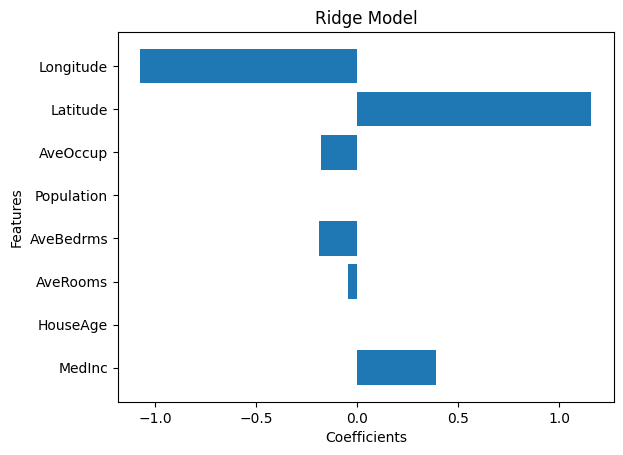

Ridge Model 
 MSE: 0.4207219325835488 
 R2: 0.6292233419181112 

      Feature     Coeff
0      MedInc  0.350421
1    HouseAge -0.000000
2    AveRooms -0.000000
3   AveBedrms -0.000000
4  Population  0.000095
5    AveOccup -0.043126
6    Latitude  0.000000
7   Longitude -0.000000


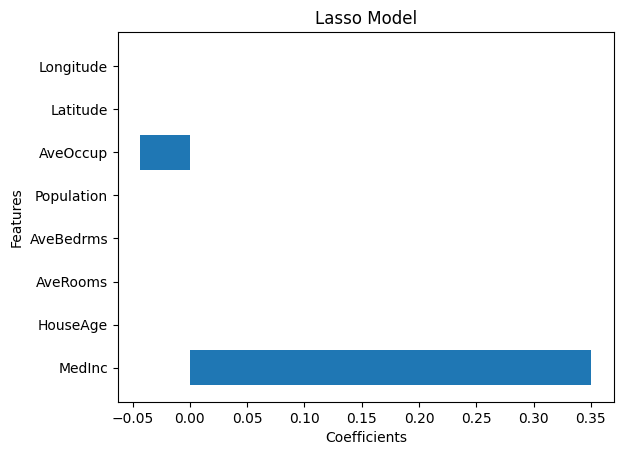

Lasso Model 
 MSE: 0.48252760502025854 
 R2: 0.5747548226853127 

      Feature     Coeff
0      MedInc  0.354130
1    HouseAge  0.000000
2    AveRooms -0.000000
3   AveBedrms -0.000000
4  Population  0.000097
5    AveOccup -0.120779
6    Latitude  0.000000
7   Longitude -0.000000


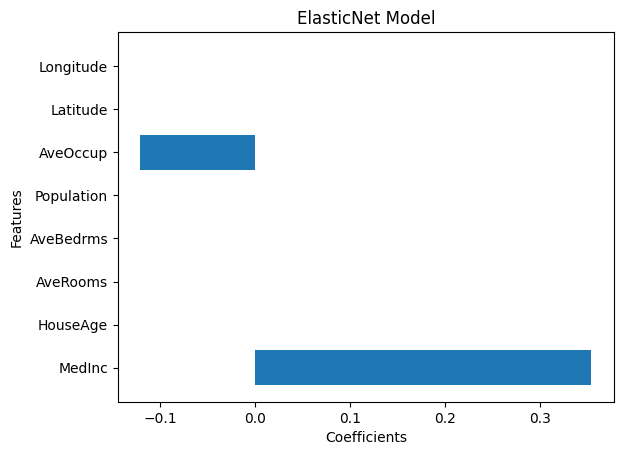

ElasticNet Model 
 MSE: 0.46633537186458646 
 R2: 0.5890248229666759 



In [1]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression,Lasso,Ridge,ElasticNet
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error,r2_score

housing_data = fetch_california_housing()

X= pd.DataFrame(housing_data.data,columns=housing_data.feature_names)
y = housing_data.target

X = X.head(350)
y = y[:350]

X = X.head(350)
y = y[:350]

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=.8,
                                                    shuffle = True,random_state = 39)
#Model Building
linear_model =LinearRegression()
lasso_model = Lasso(alpha=0.1)
ridge_model = Ridge(alpha=1.0)
elastic_model=ElasticNet(alpha=0.1)

#feature and coefficients ploting function
def coeff_plot(name,model):
    print(pd.DataFrame({"Feature":housing_data.feature_names,
                        "Coeff":model.coef_}))
    plt.barh(housing_data.feature_names,model.coef_)
    plt.title(name)
    plt.xlabel("Coefficients")
    plt.ylabel("Features")
    plt.show()

#model Evaluation
models = {
    "Linear Model": linear_model,
    "Ridge Model": ridge_model,
    "Lasso Model": lasso_model,
    "ElasticNet Model": elastic_model
}

for name,model in models.items():
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test,y_pred)
    r2 = r2_score(y_test,y_pred)
    coeff_plot(name,model)

    print(name,'\n',"MSE:",mse,'\n',"R2:",r2,'\n')


In [2]:
"""
#model training
linear_model.fit(X_train,y_train)
lasso_model.fit(X_train,y_train)
ridge_model.fit(X_train,y_train)
elastic_model.fit(X_train,y_train)

# Print coefficients
print("Linear Regression Coefficients")
print(linear_model.coef_)

print("Ridge Regression Coefficients")
print(ridge_model.coef_)

print("Lasso Regression Coefficients")
print(lasso_model.coef_)

print("Elastic Net Coefficients")
print(elastic_model.coef_)"""

'\n#model training\nlinear_model.fit(X_train,y_train)\nlasso_model.fit(X_train,y_train)\nridge_model.fit(X_train,y_train)\nelastic_model.fit(X_train,y_train)\n\n# Print coefficients\nprint("Linear Regression Coefficients")\nprint(linear_model.coef_)\n\nprint("Ridge Regression Coefficients")\nprint(ridge_model.coef_)\n\nprint("Lasso Regression Coefficients")\nprint(lasso_model.coef_)\n\nprint("Elastic Net Coefficients")\nprint(elastic_model.coef_)'